In [2]:

from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image


In [3]:

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "trashcan_cleaned_final"

ANNOTATIONS_PATH = DATASET_PATH / "annotations"

print("Dataset:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())


Dataset: c:\Users\mariem\Documents\trashcan-dl-mlops\data\processed\trashcan_cleaned_final
Dataset exists: True


In [4]:

with open(ANNOTATIONS_PATH / "instances_train.json", "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

category_names = {
    category["id"]: category["name"]
    for category in categories
}

print("Images:", len(images))
print("Annotations:", len(annotations))
print("Classes:", category_names)


Images: 5233
Annotations: 4942
Classes: {1: 'trash_etc', 2: 'trash_plastic', 3: 'trash_metal', 4: 'trash_wood', 5: 'trash_fabric', 6: 'trash_fishing_gear', 7: 'trash_paper', 8: 'trash_rubber'}


In [5]:

annotations_by_image = {}

for ann in annotations:
    image_id = ann["image_id"]

    if image_id not in annotations_by_image:
        annotations_by_image[image_id] = []

    annotations_by_image[image_id].append(ann)

print("Images avec annotations:", len(annotations_by_image))
print("Images négatives:", len(images) - len(annotations_by_image))


Images avec annotations: 4175
Images négatives: 1058


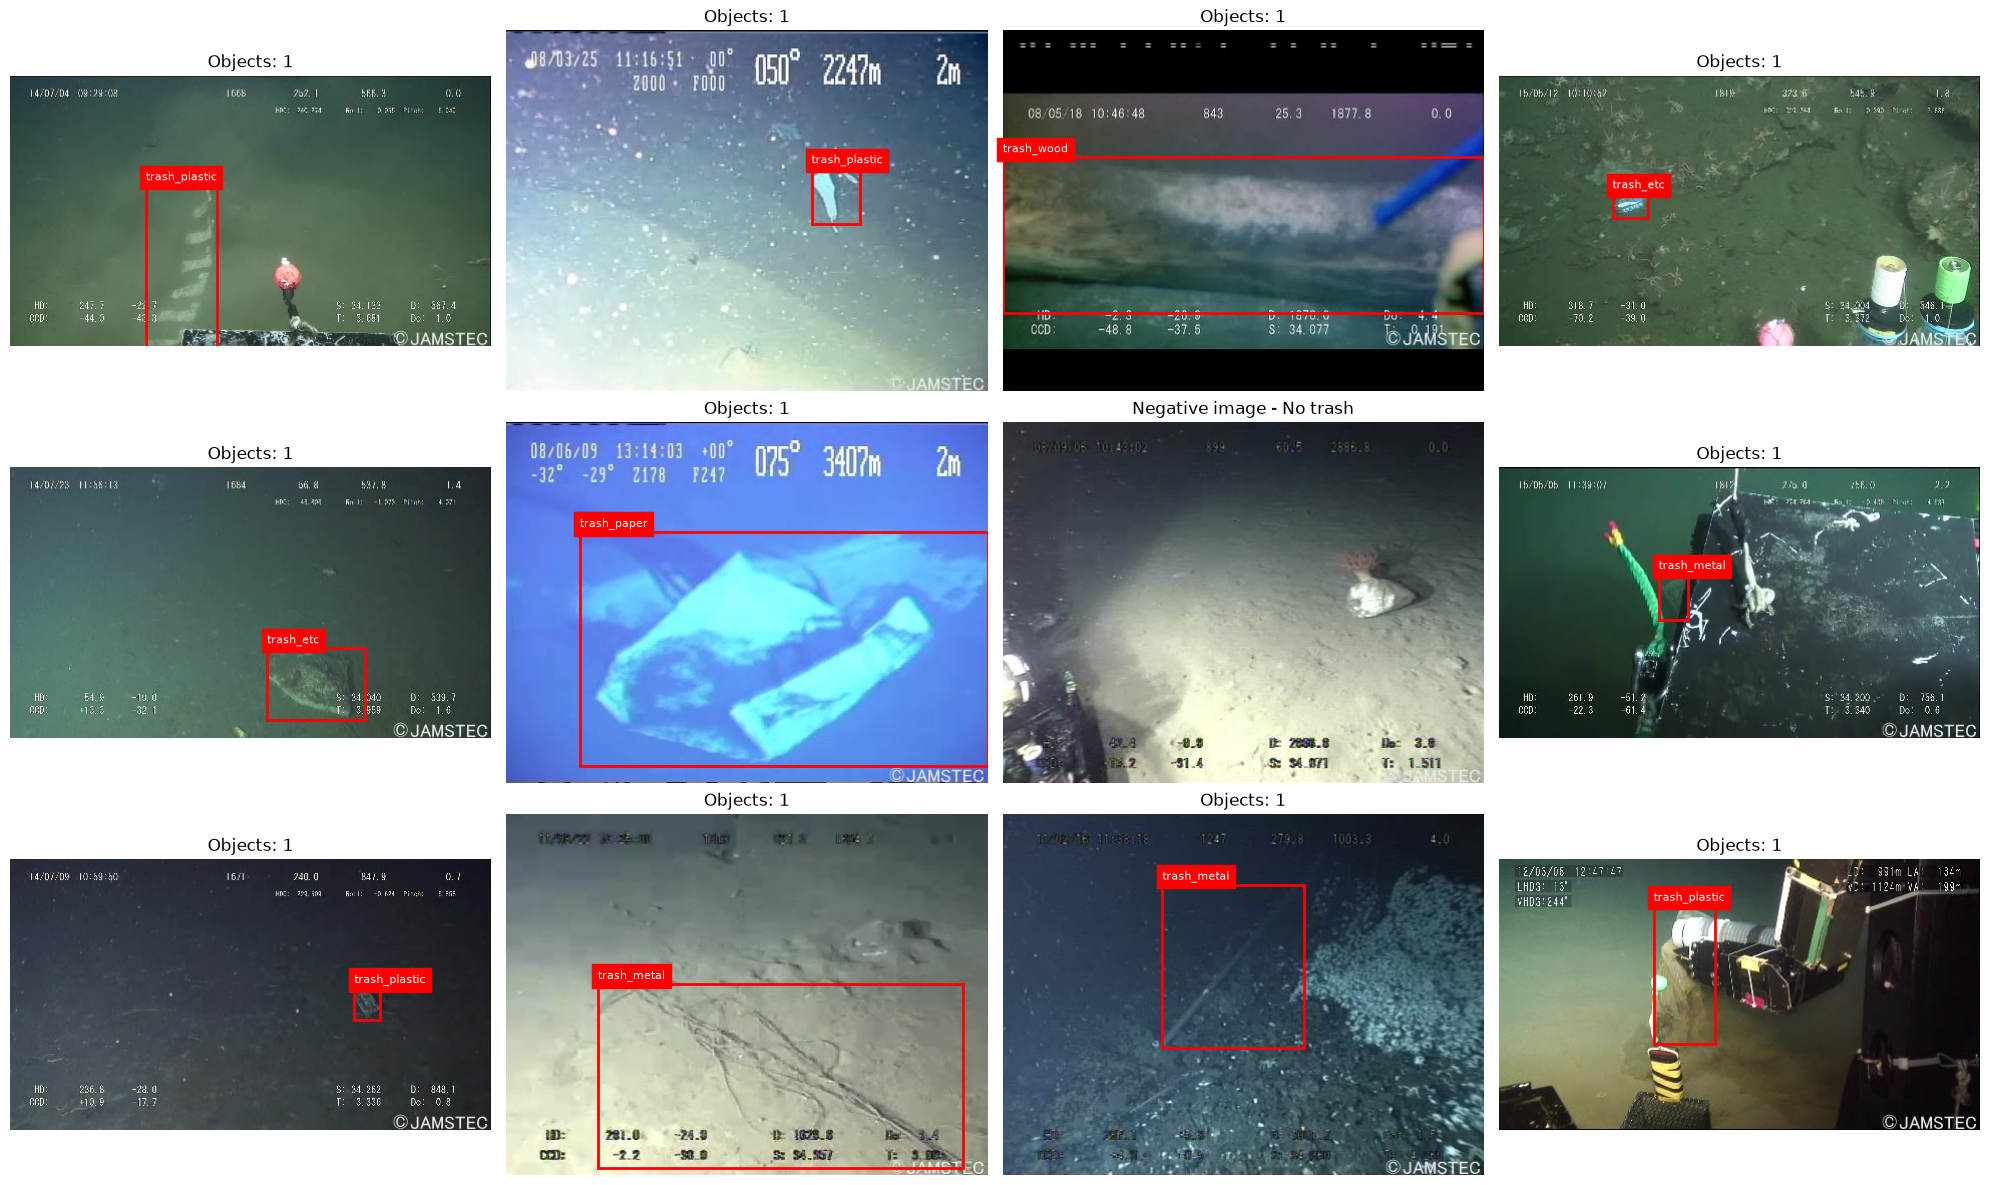

In [6]:

IMAGES_PATH = DATASET_PATH / "train" / "images"

random.seed(42)

samples = random.sample(images, min(12, len(images)))

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

for ax, image_info in zip(axes, samples):

    image_path = IMAGES_PATH / image_info["file_name"]
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)

    image_annotations = annotations_by_image.get(
        image_info["id"], []
    )

    for ann in image_annotations:

        x, y, width, height = ann["bbox"]
        class_name = category_names[ann["category_id"]]

        rectangle = patches.Rectangle(
            (x, y),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        ax.text(
            x,
            max(0, y - 5),
            class_name,
            color="white",
            fontsize=8,
            backgroundcolor="red"
        )

    if len(image_annotations) == 0:
        ax.set_title("Negative image - No trash")
    else:
        ax.set_title(f"Objects: {len(image_annotations)}")

    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

with open(ANNOTATIONS_PATH / "instances_val.json", "r", encoding="utf-8") as f:
    coco_val = json.load(f)

print("Validation images:", len(coco_val["images"]))
print("Validation annotations:", len(coco_val["annotations"]))
print("Validation classes:", len(coco_val["categories"]))


Validation images: 1249
Validation annotations: 1272
Validation classes: 8


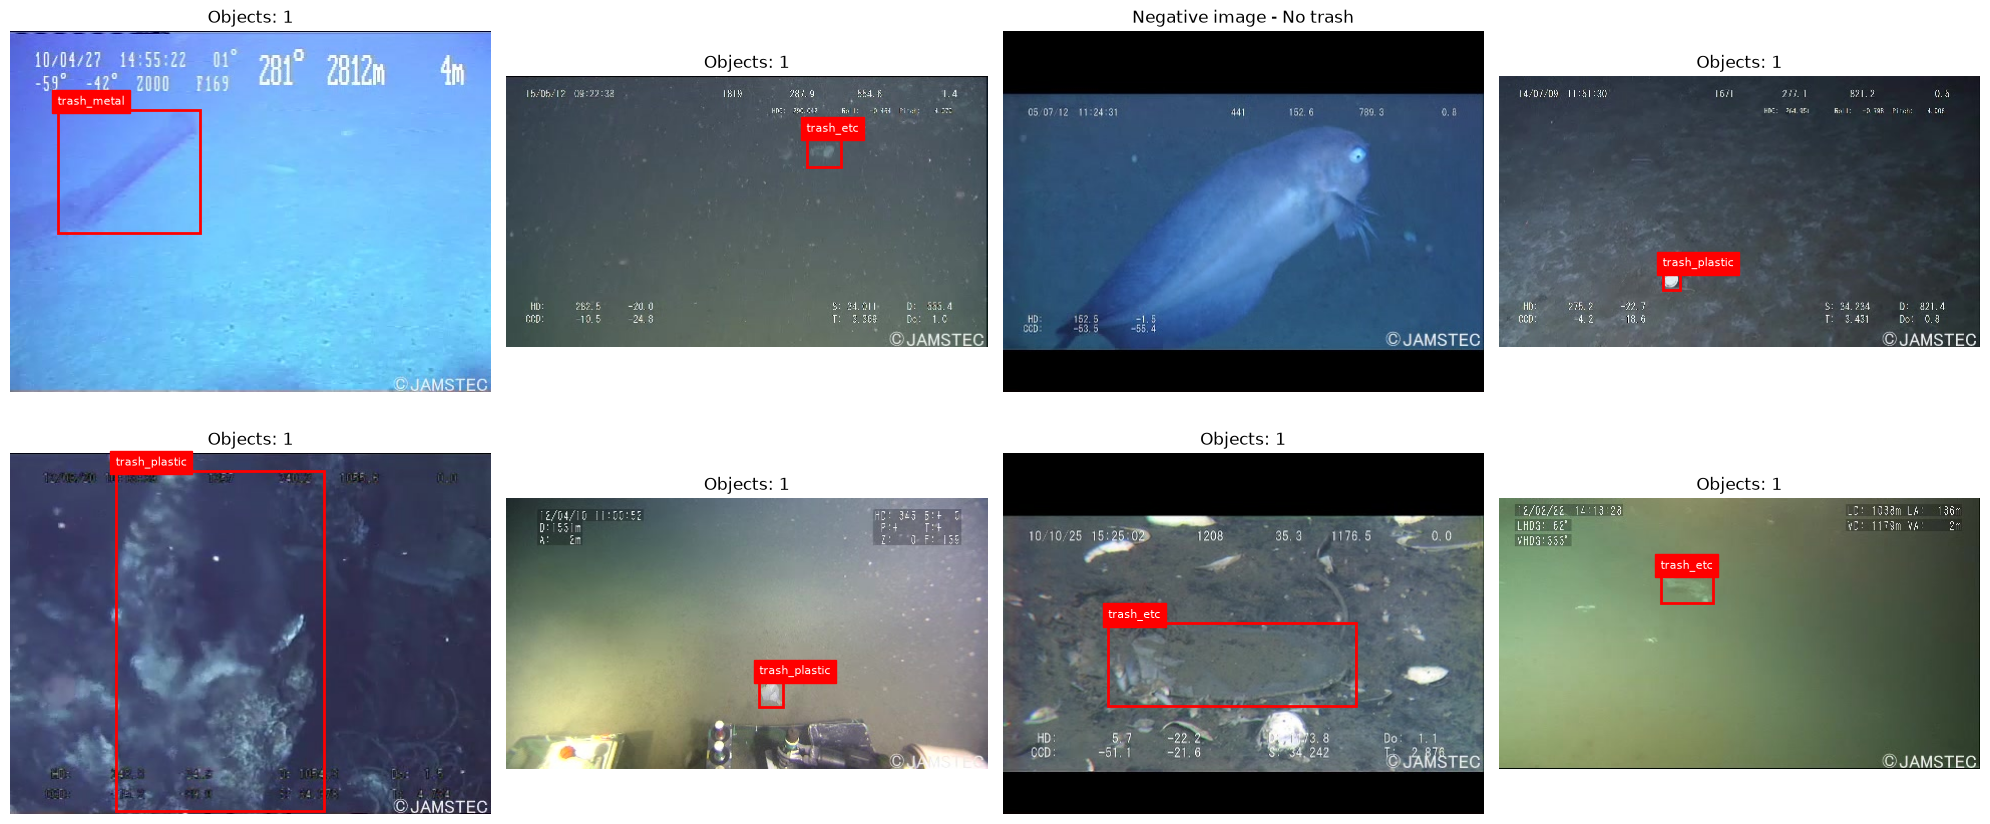

In [8]:
# Visualize 8 random validation images

val_images = coco_val["images"]
val_annotations = coco_val["annotations"]

val_annotations_by_image = {}

for ann in val_annotations:
    image_id = ann["image_id"]

    if image_id not in val_annotations_by_image:
        val_annotations_by_image[image_id] = []

    val_annotations_by_image[image_id].append(ann)

VAL_IMAGES_PATH = DATASET_PATH / "val" / "images"

random.seed(42)

val_samples = random.sample(
    val_images,
    min(8, len(val_images))
)

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for ax, image_info in zip(axes, val_samples):

    image_path = VAL_IMAGES_PATH / image_info["file_name"]
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)

    image_annotations = val_annotations_by_image.get(
        image_info["id"], []
    )

    for ann in image_annotations:

        x, y, width, height = ann["bbox"]
        class_name = category_names[ann["category_id"]]

        rectangle = patches.Rectangle(
            (x, y),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        ax.text(
            x,
            max(0, y - 5),
            class_name,
            color="white",
            fontsize=8,
            backgroundcolor="red"
        )

    if len(image_annotations) == 0:
        ax.set_title("Negative image - No trash")
    else:
        ax.set_title(f"Objects: {len(image_annotations)}")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
def validate_visual_dataset(coco, split_name):

    images = coco["images"]
    annotations = coco["annotations"]

    image_ids = {img["id"] for img in images}
    category_ids = {cat["id"] for cat in coco["categories"]}

    errors = []

    # Check annotations
    for ann in annotations:

        if ann["image_id"] not in image_ids:
            errors.append(f"Unknown image ID: {ann['image_id']}")
            continue

        if ann["category_id"] not in category_ids:
            errors.append(f"Unknown category ID: {ann['category_id']}")

        image_info = next(
            img for img in images
            if img["id"] == ann["image_id"]
        )

        x, y, w, h = ann["bbox"]
        img_width = image_info["width"]
        img_height = image_info["height"]

        if w <= 0 or h <= 0:
            errors.append(f"Invalid bbox: annotation {ann['id']}")

        if x < 0 or y < 0:
            errors.append(f"Negative coordinates: annotation {ann['id']}")

        if x + w > img_width + 0.01 or y + h > img_height + 0.01:
            errors.append(f"Bbox outside image: annotation {ann['id']}")

    print(f"\n--- {split_name.upper()} VALIDATION ---")
    print("Images:", len(images))
    print("Annotations:", len(annotations))
    print("Errors:", len(errors))

    if errors:
        print("First errors:")
        for error in errors[:10]:
            print("-", error)
    else:
        print("All annotation checks passed!")


validate_visual_dataset(coco, "train")
validate_visual_dataset(coco_val, "val")


--- TRAIN VALIDATION ---
Images: 5233
Annotations: 4942
Errors: 0
All annotation checks passed!

--- VAL VALIDATION ---
Images: 1249
Annotations: 1272
Errors: 0
All annotation checks passed!


In [10]:
def check_image_files(coco, split_name):

    images_path = DATASET_PATH / split_name / "images"

    missing_files = []

    for image_info in coco["images"]:

        image_path = images_path / image_info["file_name"]

        if not image_path.exists():
            missing_files.append(image_info["file_name"])

    print(f"\n--- {split_name.upper()} FILE CHECK ---")
    print("Expected:", len(coco["images"]))
    print("Missing:", len(missing_files))

    if len(missing_files) == 0:
        print("All image files exist!")
    else:
        print("Missing examples:", missing_files[:10])


check_image_files(coco, "train")
check_image_files(coco_val, "val")


--- TRAIN FILE CHECK ---
Expected: 5233
Missing: 0
All image files exist!

--- VAL FILE CHECK ---
Expected: 1249
Missing: 0
All image files exist!


In [11]:
try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed.")

Ultralytics is not installed.


In [12]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\mariem\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu128
CUDA available: True
Ultralytics: 8.4.214
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
